# Warsztaty analizy danych

## Czego się nauczysz

Po warsztatach będziesz umieć:

- wczytać ankietę, wybrać potrzebne odpowiedzi i przygotować tabelę do analizy;
- rozpoznać braki danych i sprawdzić liczebności poszczególnych odpowiedzi;
- tworzyć i opisywać wykresy słupkowe, zmieniać ich kolory oraz przedstawiać liczby lub procenty;
- porównywać odpowiedzi grup na wykresie, wskazując, z jakiej liczby osób obliczono procenty;
- zamaskować e-mail i telefon za pomocą wzorca regex oraz zobaczyć, jak model rozpoznaje nazwę osoby lub miejsca z kontekstu.

## Jak pracować z notatnikiem

To **wersja z odpowiedziami** do wszystkich **8 ćwiczeń**. Uruchamiaj kod po kolei, aby wrócić do wybranego miejsca zajęć. Do samodzielnej pracy otwórz [wersję warsztatową](https://colab.research.google.com/github/bajon1/Data-Analysis-Workshop/blob/main/notebooks/workshop.ipynb).

## Na jakich danych pracujemy

[Ankieta OSMI z 2014 roku](https://www.kaggle.com/datasets/osmi/mental-health-in-tech-survey) dotyczy zdrowia psychicznego w branży technologicznej. Wybieramy sześć pytań o pracę i wsparcie. Dane osobiste i komentarze pozostają poza ćwiczeniami. Wyniki opisują tę ankietę, a nie diagnozy czy całą populację.


In [1]:
# Uruchom tę komórkę raz, aby udostępnić moduły pomocnicze warsztatów.
import io
import os
import sys
import zipfile
from pathlib import Path
from urllib.request import urlopen

# Pobierz wszystkie pliki repozytorium, w tym moduły pomocnicze, raz na sesję Colaba.
if "google.colab" in sys.modules:
    REPO_DIR = Path("/content/Data-Analysis-Workshop-main")
    if not REPO_DIR.is_dir():
        archive_url = "https://github.com/bajon1/Data-Analysis-Workshop/archive/refs/heads/main.zip"
        with urlopen(archive_url, timeout=60) as response:
            with zipfile.ZipFile(io.BytesIO(response.read())) as archive:
                archive.extractall(REPO_DIR.parent)
else:
    REPO_DIR = Path.cwd()
    if REPO_DIR.name == "notebooks":
        REPO_DIR = REPO_DIR.parent

os.chdir(REPO_DIR)
if str(REPO_DIR) not in sys.path:
    sys.path.insert(0, str(REPO_DIR))
print(f"Repozytorium warsztatów: {REPO_DIR}")


Repozytorium warsztatów: C:\Users\piotr\Projects\Data-Analysis-Workshop


## Część 0: Przygotowanie — otwieramy ankietę

Jeden wiersz to odpowiedzi jednej osoby, a jedna kolumna — jedno pytanie.

Uruchom kod poniżej przyciskiem po lewej. Pobierze plik `survey.csv` i otworzy go jako tabelę **df_raw**. Nie trzeba wcześniej pobierać pliku ręcznie.

Pod kodem znajdziesz słownik kolumn. Do ćwiczeń wybierzemy sześć pytań i nazwiemy tę mniejszą tabelę **df**.


In [2]:
%pip -q install kagglehub

import kagglehub
import pandas as pd
import matplotlib.pyplot as plt

data_file = kagglehub.dataset_download(
    "osmi/mental-health-in-tech-survey",
    path="survey.csv",
)
df_raw = pd.read_csv(data_file)
print("Odpowiedzi na ankietę:", len(df_raw))



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


C:\Users\piotr\Projects\Data-Analysis-Workshop\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Odpowiedzi na ankietę: 1259


### Słownik kolumn pliku źródłowego

<details>
<summary>Rozwiń pełny słownik — materiał do sprawdzenia w razie potrzeby</summary>

Opisy według [karty danych autorów](https://www.kaggle.com/datasets/osmi/mental-health-in-tech-survey).

| Kolumna | Opis |
|---|---|
| `Timestamp` | Czas przesłania odpowiedzi na ankietę. |
| `Age` | Wiek. |
| `Gender` | Płeć. |
| `Country` | Kraj. |
| `state` | Stan lub terytorium, jeśli respondent mieszka w Stanach Zjednoczonych. |
| `self_employed` | Czy pracujesz na własny rachunek? |
| `family_history` | Czy w Twojej rodzinie występowały zaburzenia psychiczne? |
| `treatment` | Czy szukałeś lub szukałaś leczenia w związku ze zdrowiem psychicznym? |
| `work_interfere` | Jeśli doświadczasz problemów ze zdrowiem psychicznym, czy utrudniają Ci one pracę? |
| `no_employees` | Ile osób zatrudnia Twoja firma lub organizacja? |
| `remote_work` | Czy pracujesz zdalnie, poza biurem, przez co najmniej 50% czasu? |
| `tech_company` | Czy Twój pracodawca jest przede wszystkim firmą lub organizacją technologiczną? |
| `benefits` | Czy pracodawca zapewnia świadczenia dotyczące zdrowia psychicznego? |
| `care_options` | Czy znasz możliwości opieki w zakresie zdrowia psychicznego zapewniane przez pracodawcę? |
| `wellness_program` | Czy pracodawca omawiał zdrowie psychiczne w ramach programu wspierania zdrowia pracowników? |
| `seek_help` | Czy pracodawca udostępnia materiały dotyczące zdrowia psychicznego i szukania pomocy? |
| `anonymity` | Czy przy korzystaniu ze wsparcia dotyczącego zdrowia psychicznego lub używania substancji chroniona jest anonimowość? |
| `leave` | Jak łatwo jest uzyskać zwolnienie lub urlop z powodu problemów ze zdrowiem psychicznym? |
| `mental_health_consequence` | Czy rozmowa z pracodawcą o zdrowiu psychicznym mogłaby mieć negatywne konsekwencje? |
| `phys_health_consequence` | Czy rozmowa z pracodawcą o zdrowiu fizycznym mogłaby mieć negatywne konsekwencje? |
| `coworkers` | Czy byłbyś skłonny lub byłabyś skłonna rozmawiać ze współpracownikami o zdrowiu psychicznym? |
| `supervisor` | Czy byłbyś skłonny lub byłabyś skłonna rozmawiać z bezpośrednim przełożonym o zdrowiu psychicznym? |
| `mental_health_interview` | Czy poruszyłbyś lub poruszyłabyś temat zdrowia psychicznego podczas rozmowy kwalifikacyjnej? |
| `phys_health_interview` | Czy poruszyłbyś lub poruszyłabyś temat zdrowia fizycznego podczas rozmowy kwalifikacyjnej? |
| `mental_vs_physical` | Czy pracodawca traktuje zdrowie psychiczne równie poważnie jak zdrowie fizyczne? |
| `obs_consequence` | Czy słyszałeś lub słyszałaś o negatywnych konsekwencjach dla współpracowników z problemami zdrowia psychicznego albo je zaobserwowałeś lub zaobserwowałaś? |
| `comments` | Dodatkowe komentarze tekstowe. Nie używamy ich w kursie. |

`treatment` oznacza szukanie leczenia, nie diagnozę. Wybranie kilku kolumn samo w sobie nie zapewnia anonimowości.

</details>


### Nasza tabela robocza

Pracujemy z sześcioma pytaniami:

| Kolumna | Czego dotyczy? |
|---|---|
| `remote_work` | Praca zdalna przez co najmniej połowę czasu. |
| `self_employed` | Samozatrudnienie. |
| `benefits` | Świadczenia pracodawcy dotyczące zdrowia psychicznego. |
| `care_options` | Znajomość możliwości opieki oferowanych przez pracodawcę. |
| `wellness_program` | Rozmowy o zdrowiu psychicznym w firmowym programie zdrowotnym. |
| `seek_help` | Materiały pracodawcy dotyczące zdrowia psychicznego i szukania pomocy. |

Zapis odpowiedzi: **Yes** — tak, **No** — nie, **Don't know** — nie wiem, **Not sure** — nie mam pewności. Zachowujemy te rozróżnienia.

Kod poniżej tworzy tabelę `df`. Nawiasy wyjaśnimy w części 1.


In [3]:
workshop_columns = [
    "remote_work",
    "self_employed",
    "benefits",
    "care_options",
    "wellness_program",
    "seek_help",
]

df = df_raw[workshop_columns].copy()
df.head()


,remote_work,self_employed,benefits,care_options,wellness_program,seek_help
0,No,NaN,Yes,Not sure,No,Yes
1,No,NaN,Don't know,No,Don't know,Don't know
2,No,NaN,No,No,No,No
3,No,NaN,No,Yes,No,No
4,Yes,NaN,Yes,No,Don't know,Don't know


## Część 1: Jak czytać krótkie polecenia

### Co zrobić, z czym i ile pokazać?

`df` jest nazwą naszej tabeli z sześcioma pytaniami. Gdy pojawia się w kodzie, chodzi właśnie o tę tabelę.

Spójrz na zapis:

```python
df.head(3)
```

Czytamy go: **„Z tabeli df pokaż pierwsze 3 wiersze”.**

| Fragment | Co oznacza tutaj? |
|---|---|
| `df` | Nasza tabela. |
| `.` | To, co jest po kropce, ma dotyczyć tej tabeli. |
| `head` | Pokaż początek tabeli, czyli jej pierwsze wiersze. |
| `(3)` | Pokaż 3 wiersze. Liczbę wpisujemy między otwierającym `(` a zamykającym `)` nawiasem. |

Zmiana `3` na `2` zmieni liczbę pokazanych wierszy. Sama tabela pozostanie taka sama.

Pozostałe zapisy w najbliższej komórce przeczytasz tak:

| Zapis | Wynik                                                                 |
|---|-----------------------------------------------------------------------|
| `len(df)` | Oblicza liczbę wierszy.                                               |
| `print("Cześć")` | Tworzy napis Cześć. Cudzysłowy oznaczają tekst.                       |
| `df.head()` | Pierwsze 5 wierszy - domyślna wartość, gdy jej nie podamy.            |
| `df.shape` | Pokazuje wierszy i kolumn; zapis bez `()` bo to "znana" wartość tabeli. |

W `len(df)` zaczynamy od tego, co zrobić — policzyć — a w nawiasach podajemy, co liczymy: `df`. W `df.head(3)` zaczynamy od tabeli, a po kropce dopisujemy, co z nią zrobić.

Nawiasy `()` pojawiają się w poleceniach do wykonania, ale ich zawartość zależy od polecenia: w `len(df)` podajemy tabelę, w `head(3)` liczbę wierszy, a w `print("Cześć")` tekst do pokazania.

Możemy też połączyć znane elementy:

```python
print("Liczba wierszy:", len(df))
```

Najpierw `len(df)` policzy wiersze. Potem `print(...)` wyświetli napis „Liczba wierszy:” i obliczoną liczbę. Przecinek oddziela te dwie rzeczy do wyświetlenia. Wewnętrzny nawias zamyka liczenie, a zewnętrzny — całe polecenie wyświetlania.

Jeszcze jeden przydatny zapis:

```python
liczba = len(df)
```

Czytamy go: **„Policz wiersze w df i zapamiętaj wynik pod nazwą liczba”.** Pojedyncze `=` służy właśnie do nadawania takiej nazwy. Później `print(liczba)` pokaże zapamiętany wynik.


In [4]:
print("Liczba wierszy:", len(df))
print("Wiersze i kolumny:", df.shape)
df.head(3)


Liczba wierszy: 1259
Wiersze i kolumny: (1259, 6)


,remote_work,self_employed,benefits,care_options,wellness_program,seek_help
0,No,NaN,Yes,Not sure,No,Yes
1,No,NaN,Don't know,No,Don't know,Don't know
2,No,NaN,No,No,No,No


### Jak wybrać jedną kolumnę, a jak kilka?

**Po nazwie:**

```python
df["benefits"]
```

Czytamy: **„Z tabeli df wybierz kolumnę benefits”.** Tekst w cudzysłowach to dokładny nagłówek. Pandas odnajduje kolumnę po nazwie — nie musisz znać jej numeru. Pisownia i wielkość liter muszą się zgadzać.

**Kilka kolumn:**

```python
df[["benefits", "care_options"]]
```

| Nawiasy | Zadanie |
|---|---|
| Wewnętrzne: `["benefits", "care_options"]` | Lista nazw oddzielonych przecinkiem. |
| Zewnętrzne: `df[...]` | Wybór kolumn z tej listy. |

Kolejność nazw ustala kolejność kolumn w wyniku.

### Po numerze miejsca: iloc

Pozycje liczymy **od zera**:

| Pozycja | 0 | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|---|
| Kolumna | remote_work | self_employed | benefits | care_options | wellness_program | seek_help |

```python
df.iloc[:, [2, 3]]
```

To znów kolumny **benefits** i **care_options**. Przed przecinkiem `:` oznacza wszystkie wiersze; po przecinku podajemy numery kolumn, bez cudzysłowów.

**Zakres sąsiadujących kolumn:**

```python
df.iloc[:, 0:3]
```

`0:3` to **„od 0 do miejsca przed 3”**, czyli pozycje **0, 1, 2**. Dla oddzielnych miejsc użyj listy, np. `[0, 4]`.

Wybór po numerze zależy od kolejności kolumn. Uwaga: samo `df[0:3]` wybiera **wiersze**; do kolumn według pozycji używamy `iloc[:, ...]`.


In [6]:
display(df[["benefits", "care_options"]].head(3))
display(df.iloc[:, [2, 3]].head(3))
df.iloc[:, 0:3].head(3)


,benefits,care_options
0,Yes,Not sure
1,Don't know,No
2,No,No


,benefits,care_options
0,Yes,Not sure
1,Don't know,No
2,No,No


,remote_work,self_employed,benefits
0,No,NaN,Yes
1,No,NaN,Don't know
2,No,NaN,No


### Ćwiczenie 1: wybierz dwa pytania

Pokaż pierwsze **5** wierszy kolumn **remote_work** i **wellness_program**, w tej kolejności. Zrób to dwukrotnie: wybierając po nazwach oraz po pozycjach kolumn. Następnie pokaż pierwsze 5 wierszy pierwszych trzech kolumn za pomocą zakresu `0:3`.

**Podpowiedź:** Przy nazwach zachowaj podwójne nawiasy. Przy pozycjach użyj `iloc`, wszystkich wierszy (`:`) i listy dwóch numerów z tabeli powyżej. W zakresie końcowy numer jest pomijany.

**Przykład do dostosowania:**

```python
df[["benefits", "care_options"]].head(3)
df.iloc[:, [2, 3]].head(3)
df.iloc[:, 2:4].head(3)
```


In [7]:
display(df[["remote_work", "wellness_program"]].head(5))
display(df.iloc[:, [0, 4]].head(5))
df.iloc[:, 0:3].head(5)


,remote_work,wellness_program
0,No,No
1,No,Don't know
2,No,No
3,No,No
4,Yes,Don't know


,remote_work,wellness_program
0,No,No
1,No,Don't know
2,No,No
3,No,No
4,Yes,Don't know


,remote_work,self_employed,benefits
0,No,NaN,Yes
1,No,NaN,Don't know
2,No,NaN,No
3,No,NaN,No
4,Yes,NaN,Yes


### Wybieramy wiersze za pomocą pytania

Chcemy zostawić osoby pracujące zdalnie:

```python
df["remote_work"] == "Yes"
```

Czytamy: **„Czy odpowiedź w remote_work jest równa Yes?”** Znak `==` porównuje obie strony, osobno dla każdego wiersza.

Filtr działa jak bramka przepuszczająca pasujące odpowiedzi:

| Wiersz (przykład) | remote_work | Czy to Yes? | Filtr |
|---|---|---|---|
| A | No | `False` — nie | Pomiń. |
| B | Yes | `True` — tak | Zostaw. |
| C | Yes | `True` — tak | Zostaw. |
| D | No | `False` — nie | Pomiń. |

**Nie pomyl dwóch zapisów:**

| Zapis | Znaczenie |
|---|---|
| `liczba = 3` | Zapamiętaj 3 pod nazwą liczba. |
| `liczba == 3` | Czy liczba wynosi 3? Wynik: True albo False. |

```python
works_remotely = df["remote_work"] == "Yes"
remote_workers = df[works_remotely]
remote_workers.head(3)
```

1. Zadaj pytanie i zapamiętaj odpowiedzi True/False.
2. Zostaw w `df` tylko wiersze oznaczone True.
3. Pokaż pierwsze 3 pasujące wiersze.


In [8]:
works_remotely = df["remote_work"] == "Yes"
print("Odpowiedzi na pytanie o pierwsze 5 wierszy:")
print(works_remotely.head(5))
remote_workers = df[works_remotely]
remote_workers.head(3)


Odpowiedzi na pytanie o pierwsze 5 wierszy:
0    False
1    False
2    False
3    False
4     True
Name: remote_work, dtype: bool


,remote_work,self_employed,benefits,care_options,wellness_program,seek_help
4,Yes,NaN,Yes,No,Don't know,Don't know
6,Yes,NaN,No,No,No,No
7,Yes,NaN,No,Yes,No,No


### Ćwiczenie 2: przygotuj podgląd wsparcia dla osób pracujących zdalnie

Chcesz przyjrzeć się świadczeniom i znajomości opieki w grupie pracującej zdalnie. Wybierz osoby z `remote_work` równym **Yes**, wypisz liczebność całej tej grupy i pokaż pierwsze **4** wiersze tylko kolumn **benefits** i **care_options**.

**Podpowiedź:** Połącz cztery operacje: pytanie z `==`, wybór wierszy, wybór kolumn oraz podgląd `head`. Liczebność grupy policz przez `len` przed ograniczeniem podglądu do 4 wierszy.

**Przykład do dostosowania:**

```python
matching = df["remote_work"] == "No"
selected = df[matching]
print("Liczba osób w grupie:", len(selected))
selected[["wellness_program", "seek_help"]].head(2)
```


In [10]:
remote_rows = df["remote_work"] == "Yes"
remote_group = df[remote_rows]
print("Liczba osób w grupie:", len(remote_group))
remote_group[["benefits", "care_options"]].head(4)


Liczba osób w grupie: 376


,benefits,care_options
4,Yes,No
6,No,No
7,No,Yes
10,Don't know,No


### Ćwiczenie 3: sprawdź grupę, która nie wie o świadczeniach

Chcesz zaplanować komunikację o wsparciu. Wybierz osoby z odpowiedzią **Don't know** w **benefits**. Wypisz liczbę osób w tej grupie, a następnie pokaż pierwsze **6** wierszy kolumn **remote_work** i **seek_help**. Czy sam podgląd pozwala już opisać wszystkie odpowiedzi tej grupy?

**Podpowiedź:** Wybierz grupę na podstawie jednej kolumny, a w wyniku pokaż dwie inne. Tekst `"Don't know"` umieść w podwójnych cudzysłowach. `head(6)` pokazuje tylko fragment grupy.

**Przykład do dostosowania:**

```python
matching = df["care_options"] == "Not sure"
selected = df[matching]
print("Liczba osób w grupie:", len(selected))
selected[["remote_work", "wellness_program"]].head(2)
```


In [11]:
unknown_benefits = df["benefits"] == "Don't know"
communication_group = df[unknown_benefits]
print("Liczba osób w grupie:", len(communication_group))
communication_group[["remote_work", "seek_help"]].head(6)
# Podgląd obejmuje tylko 6 pierwszych wierszy; nie opisuje rozkładu całej grupy.


Liczba osób w grupie: 408


,remote_work,seek_help
1,No,Don't know
9,No,Don't know
10,Yes,No
11,Yes,No
13,No,Don't know
14,No,Don't know


## Część 2: Czyszczenie — sprawdzamy braki

### Zliczamy brakujące odpowiedzi

**No, Don't know i Not sure to zapisane odpowiedzi, a nie braki.** Puste miejsce może być wyświetlane jako `NaN`.

Wcześniej `== "Yes"` pytało: **„Czy to Yes?”**. Teraz `isna()` pyta: **„Czy tu brakuje odpowiedzi?”**.

| Przykładowa wartość | `== "Yes"` | `isna()` |
|---|---|---|
| Yes | True | False |
| No | False | False |
| Don't know / Not sure | False | False |
| brak (NaN) | False | True |

```text
odpowiedzi:  Yes     [pusto]    No     [pusto]
isna():      False   True      False  True
sum():       0   +   1     +   0  +   1     = 2 braki
```

Przy sumowaniu True liczy się jako 1, a False jako 0. Dlatego **`df.isna().sum()` znajduje braki i liczy je w każdej kolumnie**.

Używaj `isna()`, a nie `== "NaN"` — tekst w cudzysłowach nie oznacza pustego miejsca.


In [12]:
missing_answers = df.isna().sum()
missing_answers


remote_work          0
self_employed       18
benefits             0
care_options         0
wellness_program     0
seek_help            0
dtype: int64

### Oznaczamy braki bez zgadywania odpowiedzi

`pd.Series(...)` tworzy jedną kolumnę, a `None` oznacza tu brak.

`fillna("Nie podano")` wstawia etykietę tylko w puste miejsca. Nie zmienia Yes ani No i nie zgaduje odpowiedzi.

`copy()` tworzy osobną kopię tabeli. Wynik zamiany zapamiętujemy przez `df_clean = df_clean.fillna(...)`.


In [14]:
example_answers = pd.Series(["Yes", None, "No"])
example_answers.fillna("Nie podano")


0           Yes
1    Nie podano
2            No
dtype: str

### Ćwiczenie 4: oznacz brakujące odpowiedzi

W przygotowanej kopii **df_clean** zastąp wyłącznie puste miejsca etykietą **"Brak odpowiedzi"**. Zapamiętaj wynik pod tą samą nazwą i pokaż pierwsze **3** wiersze.

**Podpowiedź:** Zacznij od `df_clean`, dopisz `.fillna(...)` i przypisz wynik przez `df_clean = ...`. Nie zastępuj odpowiedzi No ani Don't know.

**Przykład do dostosowania:**

```python
example_answers = pd.Series(["Yes", None, "No"])
example_answers.fillna("Nie podano")
```


In [15]:
df_clean = df.copy()

# Polecenie: w df_clean oznacz braki jako "Brak odpowiedzi" i zapamiętaj wynik.
df_clean = df_clean.fillna("Brak odpowiedzi")
df_clean.head(3)


,remote_work,self_employed,benefits,care_options,wellness_program,seek_help
0,No,Brak odpowiedzi,Yes,Not sure,No,Yes
1,No,Brak odpowiedzi,Don't know,No,Don't know,Don't know
2,No,Brak odpowiedzi,No,No,No,No


### Sprawdzamy efekt zamiany przez value_counts()

`value_counts()` pokazuje **każdą odpowiedź i liczbę jej wystąpień**. Dodatek `dropna=False` pokazuje również pozostałe braki.

Porównaj **self_employed przed i po zamianie**: liczba Brak odpowiedzi powinna odpowiadać wcześniejszej liczbie NaN, a Yes i No pozostać bez zmian. Zobaczysz też ewentualne inne napisy; `fillna()` zmienia tylko puste miejsca.

Kod poniżej odtwarza wspólną tabelę po ćwiczeniu 4. `display(...)` pozwala pokazać dwa zestawienia w jednej komórce.

Identyczne zestawy odpowiedzi mogą pochodzić od różnych osób — nie usuwamy ich.


In [16]:
df_clean = df.copy()
df_clean = df_clean.fillna("Brak odpowiedzi")

print("Przed zamianą:")
display(df["self_employed"].value_counts(dropna=False))
print("Po zamianie:")
display(df_clean["self_employed"].value_counts(dropna=False))


Przed zamianą:


self_employed
No     1095
Yes     146
NaN      18
Name: count, dtype: int64

Po zamianie:


self_employed
No                 1095
Yes                 146
Brak odpowiedzi      18
Name: count, dtype: int64

### Ćwiczenie 5: przygotuj zestawienie do raportu

Z oryginalnej tabeli **df** przygotuj raport o osobach pracujących zdalnie:

1. Wybierz `remote_work == "Yes"` i skopiuj kolumny **self_employed**, **seek_help** do `remote_report`.
2. Wypisz liczbę osób oraz braki w obu kolumnach.
3. Oznacz braki jako **Brak odpowiedzi** i pokaż pierwsze **5** wierszy.
4. Policz kategorie obu pytań, uwzględniając ewentualne braki. Dopisz jedno zdanie wniosku.

**Podpowiedź:** Połącz filtrowanie z `copy()`, `isna().sum()`, `fillna(...)` i `value_counts(dropna=False)`. Licz całą grupę; zostaw `df_clean` do dalszej pracy.

**Przykład do dostosowania:**

```python
matching = df["remote_work"] == "No"
example_report = df[matching][["benefits", "care_options"]].copy()
print("Osób w grupie:", len(example_report))
print(example_report.isna().sum())
example_report = example_report.fillna("Nie podano")
display(example_report.head(2))
example_report["benefits"].value_counts(dropna=False)
```


In [18]:
remote_rows = df["remote_work"] == "Yes"
remote_report = df[remote_rows][["self_employed", "seek_help"]].copy()
print("Osób w grupie:", len(remote_report))
print("Braki przed zamianą:")
print(remote_report.isna().sum())
remote_report = remote_report.fillna("Brak odpowiedzi")
display(remote_report.head(5))
display(remote_report["self_employed"].value_counts(dropna=False))
display(remote_report["seek_help"].value_counts(dropna=False))
# Sprawdzono braki oraz liczby kategorii w całej grupie pracującej zdalnie.
# Po zamianie nie ma NaN; zapisane odpowiedzi, w tym Don't know, pozostały.


Osób w grupie: 376
Braki przed zamianą:
self_employed    6
seek_help        0
dtype: int64


,self_employed,seek_help
4,Brak odpowiedzi,Don't know
6,Brak odpowiedzi,No
7,Brak odpowiedzi,No
10,Brak odpowiedzi,No
11,Brak odpowiedzi,No


self_employed
No                 268
Yes                102
Brak odpowiedzi      6
Name: count, dtype: int64

seek_help
No            201
Don't know    111
Yes            64
Name: count, dtype: int64

## Część 3: Wykresy i porównania

### Wykres słupkowy

Pytamy: **Jak respondenci odpowiadają na pytanie o świadczenia pracodawcy?**

`plot.barh()` rysuje poziome słupki: ich długość odpowiada liczbie odpowiedzi. Polecenia `plt` dodają podpisy.

Zachowaj Don't know — brak wiedzy o świadczeniu nie oznacza, że świadczenia nie ma.


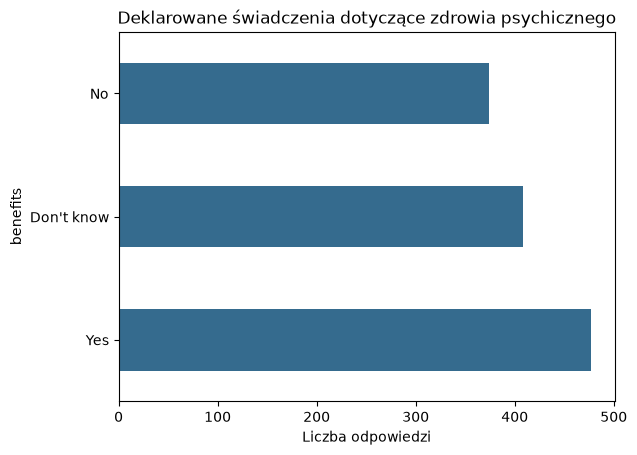

In [19]:
benefit_counts = df_clean["benefits"].value_counts()
benefit_counts.plot.barh(color="#356b8e")
plt.xlabel("Liczba odpowiedzi")
plt.title("Deklarowane świadczenia dotyczące zdrowia psychicznego")
plt.show()


### Ćwiczenie 6: dostosuj wykres

Narysuj poziomy wykres słupkowy liczebności odpowiedzi **wellness_program**. Nadaj mu tytuł wskazujący, którego pytania dotyczy.

**Podpowiedź:** Zmień kolumnę oraz tytuł. Nazwa zmiennej `counts` może pozostać taka sama. Zachowaj wszystkie kategorie odpowiedzi.

**Przykład do dostosowania:**

```python
counts = df_clean["benefits"].value_counts()
counts.plot.barh(color="#356b8e")
plt.xlabel("Liczba odpowiedzi")
plt.title("Deklarowane świadczenia pracodawcy")
plt.show()
```


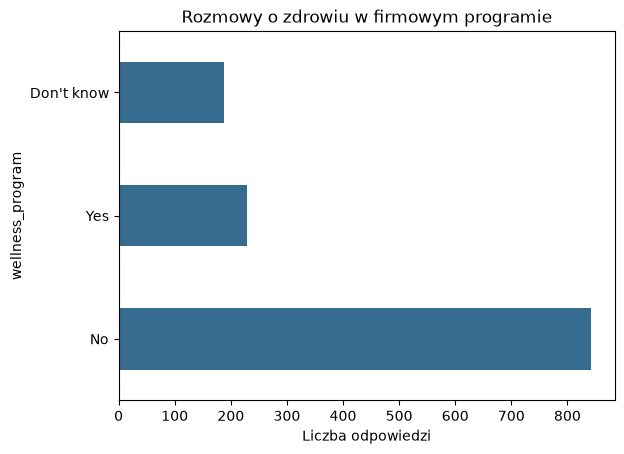

In [20]:
wellness_counts = df_clean["wellness_program"].value_counts()
wellness_counts.plot.barh(color="#356b8e")
plt.xlabel("Liczba odpowiedzi")
plt.title("Rozmowy o zdrowiu w firmowym programie")
plt.show()


### Liczebności i procenty

`value_counts(normalize=True) * 100` daje procenty, a `round(1)` zaokrągla do jednego miejsca po przecinku.

Mianownik to **wszystkie wiersze df_clean**, łącznie z Don't know i Brak odpowiedzi. Wyniki opisują tę ankietę; uczestnicy zgłaszali się sami, więc nie reprezentują wszystkich pracowników.


In [21]:
benefit_percent = df_clean["benefits"].value_counts(normalize=True) * 100
print("Mianownik:", len(df_clean), "odpowiedzi")
benefit_percent.round(1)


Mianownik: 1259 odpowiedzi


benefits
Yes           37.9
Don't know    32.4
No            29.7
Name: proportion, dtype: float64

### Porównujemy grupy

**Czy odpowiedzi benefits różnią się między osobami pracującymi zdalnie a pozostałymi?**

`pd.crosstab(...)` zlicza połączenia odpowiedzi: pierwsze pytanie wyznacza wiersze tabeli, a drugie — kolumny. Najpierw sprawdź liczebności grup.


In [23]:
benefits_by_remote_counts = pd.crosstab(
    df_clean["remote_work"],
    df_clean["benefits"],
)
benefits_by_remote_counts


benefits,Don't know,No,Yes
remote_work,,,
No,282,241,360
Yes,126,133,117


Dodatek `normalize="index"` i mnożenie przez 100 przeliczają każdą grupę na procenty — każdy wiersz sumuje się do **100%**.

Poniżej oglądamy tabelę; w ćwiczeniu 7 narysujesz wykres. `stacked=True` ułoży kategorie w jeden słupek dla każdej grupy. Sprawdź też liczebności: procenty z małych grup mogą być niestabilne.


In [33]:
benefits_by_remote_percent = pd.crosstab(
    df_clean["remote_work"],
    df_clean["benefits"],
    normalize="index",
) * 100

benefits_by_remote_percent.round(1)


benefits,Don't know,No,Yes
remote_work,,,
No,31.9,27.3,40.8
Yes,33.5,35.4,31.1


### Ćwiczenie 7: połącz znane kroki

Porównaj odpowiedzi **wellness_program** między grupami pracy zdalnej. Wyświetl tabelę liczebności, a następnie poziomy wykres procentów wewnątrz grup. Podpisz oś, tytuł i legendę.

**Podpowiedź:** Połącz dwa przykłady z `crosstab`. Zostaw `remote_work` jako pierwszą kolumnę i zmień drugą na `wellness_program`. Dodaj `normalize="index"` tylko do tabeli procentów; każdy jej wiersz ma dawać 100%.

**Przykład do dostosowania:**

```python
group_counts = pd.crosstab(df_clean["remote_work"], df_clean["benefits"])
display(group_counts)
group_percent = pd.crosstab(
    df_clean["remote_work"], df_clean["benefits"], normalize="index"
) * 100
group_percent.plot.barh(stacked=True)
plt.xlabel("Procent odpowiedzi w danej grupie pracy zdalnej")
plt.ylabel("Praca zdalna")
plt.title("Świadczenia a praca zdalna")
plt.legend(title="Odpowiedź o świadczeniach")
plt.show()
```


wellness_program,Don't know,No,Yes
remote_work,,,
No,122,586,175
Yes,66,256,54


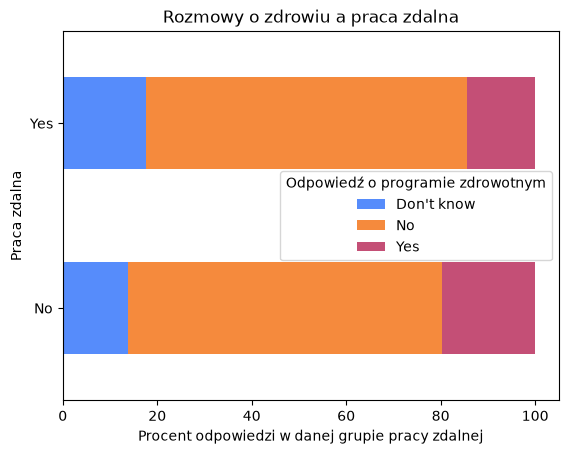

In [25]:
wellness_by_remote_counts = pd.crosstab(
    df_clean["remote_work"], df_clean["wellness_program"]
)
display(wellness_by_remote_counts)
wellness_by_remote_percent = pd.crosstab(
    df_clean["remote_work"], df_clean["wellness_program"], normalize="index"
) * 100
wellness_by_remote_percent.plot.barh(stacked=True)
plt.xlabel("Procent odpowiedzi w danej grupie pracy zdalnej")
plt.ylabel("Praca zdalna")
plt.title("Rozmowy o zdrowiu a praca zdalna")
plt.legend(title="Odpowiedź o programie zdrowotnym")
plt.show()


### Dwa dodatkowe wykresy do wypróbowania

Zmień kolumnę, kolor i tytuł w przepisach poniżej.

- `value_counts()` daje liczby; `value_counts(normalize=True) * 100` — procenty.
- `plot.bar(...)` daje pionowe słupki, `plot.barh(...)` — poziome.
- W porównaniu grup możesz zmienić `stacked=True` na `False`, aby ustawić słupki obok siebie.

Po zmianach popraw podpisy. Sam wykres nie dowodzi, że praca zdalna spowodowała różnice.


**Przepis 1: pionowe słupki z procentami.** Zmień `seek_help`, kolor i tytuł.


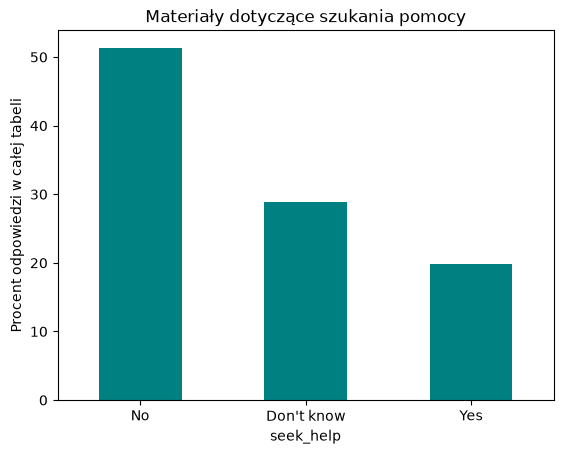

In [26]:
values = df_clean["seek_help"].value_counts(normalize=True) * 100
values.plot.bar(color="teal")
plt.ylabel("Procent odpowiedzi w całej tabeli")
plt.title("Materiały dotyczące szukania pomocy")
plt.xticks(rotation=0)
plt.show()


**Przepis 2: wykres kołowy.** Zmień kolumnę i listę kolorów. Procenty dotyczą wszystkich odpowiedzi w `df_clean`.


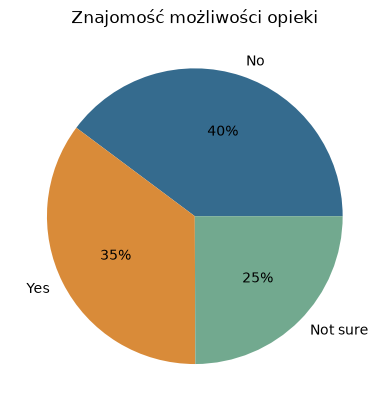

In [27]:
values = df_clean["care_options"].value_counts()
values.plot.pie(autopct="%1.0f%%", colors=["#356b8e", "#d98b39", "#72a98f", "#b3a1c9"])
plt.ylabel("")
plt.title("Znajomość możliwości opieki")
plt.show()


## Część 4: Ukrywamy dane w tekście

Pracujemy wyłącznie na **wymyślonych zdaniach**.

### Regex: wyszukiwanie według wzoru

**Regex** to sposób opisania, jak wygląda szukany fragment tekstu. Wyobraź sobie polecenie: **„Znajdź coś, co wygląda jak adres e-mail, i zasłoń to”.**

```text
Contact john@example.org.  →  Contact [EMAIL].
```

Długi zapis w `email_pattern` to gotowy wzór do skopiowania — nie musisz znać znaczenia każdego znaku. Rozpoznaje typowy zapis e-maila, m.in. znak **@**.

`re.sub(wzorzec, zamiennik, tekst)` oznacza: **znajdź pasujące fragmenty i zastąp je podanym napisem**. Ten przykładowy wzór może pominąć niektóre adresy.


In [29]:
import re

synthetic_text = "John Smith lives in London. Contact john@example.org or +48 123 456 789."
email_pattern = r"[\w.+-]+@[\w.-]+\.[A-Za-z]{2,}"

masked_text = re.sub(email_pattern, "[EMAIL]", synthetic_text)
print("Przed:", synthetic_text)
print("Po:   ", masked_text)


Przed: John Smith lives in London. Contact john@example.org or +48 123 456 789.
Po:    John Smith lives in London. Contact [EMAIL] or +48 123 456 789.


Dla telefonu **+48 123 456 789** skopiuj wzór:

```python
phone_pattern = r"\+48 \d{3} \d{3} \d{3}"
```

Czytamy: **plus, 48 i trzy grupy po trzy cyfry, oddzielone spacjami**. `\d{3}` to zapis „trzy cyfry”. Inny sposób zapisania numeru może nie pasować.


### Ćwiczenie 8: ukryj drugi rodzaj danych

Zaczynając od **masked_text**, zastąp numer telefonu etykietą **[TELEFON]**. E-mail ma pozostać zamaskowany. Wyświetl wynik i sprawdź, jakie dane nadal można odczytać.

**Podpowiedź:** Użyj wzorca telefonu z opisu powyżej. Trzecim argumentem `re.sub(...)` powinien być `masked_text`, aby zachować wcześniejszą zamianę e-maila.

**Przykład do dostosowania:**

```python
example = "Kod spotkania: 123."
re.sub(r"\d{3}", "[KOD]", example)
```


In [30]:
phone_pattern = r"\+48 \d{3} \d{3} \d{3}"
phone_masked = re.sub(phone_pattern, "[TELEFON]", masked_text)
print(phone_masked)
# E-mail i telefon są ukryte, ale nadal widać imię i nazwisko oraz miasto.


John Smith lives in London. Contact [EMAIL] or [TELEFON].


### Rozpoznawanie osoby i miejsca z kontekstu

Model językowy korzysta także ze słów otaczających nazwę. W tym zdaniu rozpoznaje osobę i miasto:

```text
John Smith lives in London.
     ↓                  ↓
[OSOBA] lives in [MIEJSCE].
```

Model wskazuje fragmenty, a kod zamienia je na etykiety. Może się pomylić. Poniżej pobieramy angielski model spaCy, dlatego zdanie jest po angielsku.


In [31]:
# Jednorazowe przygotowanie modelu do poniższego przykładu.
%pip -q install https://github.com/explosion/spacy-models/releases/download/en_core_web_sm-3.8.0/en_core_web_sm-3.8.0-py3-none-any.whl


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [32]:
import spacy

nlp = spacy.load("en_core_web_sm")
example_text = "John Smith lives in London."
document = nlp(example_text)

# Model zwraca znalezione fragmenty i ich kategorie.
for entity in document.ents:
    print(entity.text, "→", entity.label_)

# PERSON oznacza osobę, a GPE — nazwę kraju, miasta lub regionu.
labels = {"PERSON": "[OSOBA]", "GPE": "[MIEJSCE]"}
semantic_masked = example_text
# Zamieniamy od końca, aby wcześniejsze pozycje znaków się nie przesunęły.
for entity in reversed(document.ents):
    if entity.label_ in labels:
        semantic_masked = (
            semantic_masked[:entity.start_char]
            + labels[entity.label_]
            + semantic_masked[entity.end_char:]
        )
print(semantic_masked)


John Smith → PERSON
London → GPE
[OSOBA] lives in [MIEJSCE].


Regex szuka wzoru, a model korzysta z kontekstu. **Sprawdź wynik ręcznie:** pominięte nazwisko lub szczegół opisu mogą nadal ujawniać osobę. Te metody nie gwarantują pełnej anonimizacji; przy danych badawczych obowiązują zgody i zasady instytucji.
